In [1]:
pip install pandas==2.2.3

Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install matplotlib==3.10.0

Note: you may need to restart the kernel to use updated packages.


In [3]:
pip install seaborn==0.13.2

Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd

from IPython.display import display, HTML
display(HTML("<style>.container { width:150% !important; }</style>"))
pd.options.display.max_columns=200
pd.options.display.max_rows=5200

import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df_outages = pd.read_csv("data/outage_report_summaries.csv")
df_services = pd.read_csv("data/cloud_service_risk_ratings.csv")
# Filter first dummy record of file
df_services = df_services[df_services['service_provider'].str.contains('BAD CLOUD EXAMPLE') == False]

In [6]:
df_outages

,outage_timestamp,source_outage_report,cloud_provider,cloud_service,regions,availability_zones,start_time,end_time,outage_status,impact,duration,duration_minutes,root_cause,resolution,downtime_period,incident_id,affected_components,mitigation_steps,cloudrisk_genai_output
0,1.704067e+09,Unknown,NaN,NaN,NaN,NaN,2024-01-01T00:00:00+00:00,2024-01-01T00:00:00,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,Source Outage Report: Unknown\nCloud Provider:...
1,1.704067e+09,outages_files/20190823-Summary of the Amazon E...,AWS,Amazon ElastiCache,ap-northeast-1,NaN,2024-01-01T00:00:00+00:00,2024-01-01T05:54:00+00:00,resolved,NaN,approximately 5 hours and 54 minutes.,354,NaN,NaN,NaN,NaN,Amazon AWS Direct Connect,NaN,Source Outage Report: outages_files/20190823-S...
2,1.704067e+09,outages_files/20190823-Summary of the Amazon E...,AWS,Amazon AWS Direct Connect,ap-northeast-1,NaN,2024-01-01T00:00:00+00:00,2024-01-01T05:54:00+00:00,resolved,NaN,approximately 5 hours and 54 minutes.,354,NaN,NaN,NaN,NaN,Amazon AWS Direct Connect,NaN,Source Outage Report: outages_files/20190823-S...
3,1.704067e+09,outages_files/20190823-Summary of the Amazon E...,AWS,rs,ap-northeast-1,NaN,2024-01-01T00:00:00+00:00,2024-01-01T05:54:00+00:00,resolved,NaN,approximately 5 hours and 54 minutes.,354,NaN,NaN,NaN,NaN,Amazon AWS Direct Connect,NaN,Source Outage Report: outages_files/20190823-S...
4,1.704067e+09,outages_files/20190823-Summary of the Amazon E...,AWS,Amazon Elastic Compute Cloud,ap-northeast-1,NaN,2024-01-01T00:00:00+00:00,2024-01-01T05:54:00+00:00,resolved,NaN,approximately 5 hours and 54 minutes.,354,NaN,NaN,NaN,NaN,Amazon AWS Direct Connect,NaN,Source Outage Report: outages_files/20190823-S...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5522,1.722351e+09,outages_files/Summary of the AWS Service Event...,AWS,rs,us-east-1,NaN,2024-07-30T14:45:00+00:00,2024-07-30T22:37:00+00:00,investigating,none,7 hours and 36 minutes,456,Degradation of one of the internally-used cell...,NaN,Until CloudWatch Logs recovery,NaN,Amazon Web Services (AWS),NaN,Source Outage Report: outages_files/Summary of...
5523,1.722351e+09,outages_files/Summary of the AWS Service Event...,AWS,Amazon AWS Lambda,us-east-1,NaN,2024-07-30T14:45:00+00:00,2024-07-30T22:37:00+00:00,investigating,none,7 hours and 36 minutes,456,Degradation of one of the internally-used cell...,NaN,Until CloudWatch Logs recovery,NaN,Amazon Web Services (AWS),NaN,Source Outage Report: outages_files/Summary of...
5524,1.722351e+09,outages_files/Summary of the AWS Service Event...,AWS,Amazon Kinesis,us-east-1,NaN,2024-07-30T14:45:00+00:00,2024-07-30T22:37:00+00:00,investigating,none,7 hours and 36 minutes,456,Degradation of one of the internally-used cell...,NaN,Until CloudWatch Logs recovery,NaN,Amazon Web Services (AWS),NaN,Source Outage Report: outages_files/Summary of...
5525,1.722351e+09,outages_files/Summary of the AWS Service Event...,AWS,Amazon Redshift,us-east-1,NaN,2024-07-30T14:45:00+00:00,2024-07-30T22:37:00+00:00,investigating,none,7 hours and 36 minutes,456,Degradation of one of the internally-used cell...,NaN,Until CloudWatch Logs recovery,NaN,Amazon Web Services (AWS),NaN,Source Outage Report: outages_files/Summary of...


In [7]:
df_services

,database_key_id,service_name,service_provider,global_or_by_regions,region,availability_zone,service_load_at_customer_low_medium_high_very_high_1_2_3_4,customer_service_type_b2c_or_b2b_1_yes_0_no,customer_service_up_hours_8h_day_12h_day_24h_day,customer_service_annual_workdays,service_sla_0_99_9999_for_tier1,service_sla_0_99_9999_for_tier2,service_sla_0_99_9999_for_tier3,service_sla_0_99_9999_for_tier4,percentage_service_credit_back_tier1,percentage_service_credit_back_tier2,percentage_service_credit_back_tier3,percentage_service_credit_back_tier4,webscraper_annual_period_service_down_per_year_in_minutes,annual_service_minutes_up_365_24_60_equals_525600,expected_annual_service_minutes_up_by_sla_tier1,expected_annual_service_minutes_up_by_sla_tier2,expected_annual_service_minutes_up_by_sla_tier3,expected_annual_service_minutes_up_by_sla_tier4,expected_annual_service_minutes_down_by_sla_tier1,expected_annual_service_minutes_down_by_sla_tier2,expected_annual_service_minutes_down_by_sla_tier3,expected_annual_service_minutes_down_by_sla_tier4,service_debit_credit_more_than_annual_sla_tier1,expected_percentage_mins_down_inside_agreed_sla_tier1,actual_percentage_total_mins_down_from_webscraping,actual_percentage_mins_down_on_agreed_sla,gap_time_percent_between_SLA_down_actual_down,riskcoef_per_service_from_gap_expected_actual_time_down,service_sla_usage_percentage,service_traffic_coef_by_percent_down,sla_deviation_connected_risk_0_999,usage_connected_risk_0_999,annual_outage_time_days_hours_mins,remarks_outage_genai,public_locationa_and_status_genai,outages_other_impacted_services_genai,notes
1,10000000000001,AnyCast CloudFlare,Cloudflare,global,NaN,NaN,4,1,24,365,99.99999,99.99999,99.99999,99.99999,10.0,25.0,50.0,100.0,4.60,525600.0,525599.947,525599.947,525599.947,525599.947,0.053,0.053,0.053,0.053,-4.547,0.000010%,0.00087519%,0.00087519%,-0.000865%,0.000865%,8751.903466,0.000875,911.560,998.974,0 days 0h21 down,NaN,NaN,NaN,NaN
2,10000000000002,CDN CloudFlare,Cloudflare,global,NaN,NaN,4,1,24,365,99.99999,99.99999,99.99999,99.99999,10.0,25.0,50.0,100.0,4.60,525600.0,525599.947,525599.947,525599.947,525599.947,0.053,0.053,0.053,0.053,-4.547,0.000010%,0.00087519%,0.00087519%,-0.000865%,0.000865%,8751.903466,0.000875,911.560,998.974,0 days 0h21 down,NaN,NaN,NaN,NaN
3,10000000000003,Cloudflare DNS,Cloudflare,global,NaN,NaN,4,1,24,365,99.99999,99.99999,99.99999,99.99999,10.0,25.0,50.0,100.0,4.60,525600.0,525599.947,525599.947,525599.947,525599.947,0.053,0.053,0.053,0.053,-4.547,0.000010%,0.00087519%,0.00087519%,-0.000865%,0.000865%,8751.903466,0.000875,911.560,998.974,0 days 0h21 down,NaN,NaN,NaN,NaN
4,10000000000004,Cloudflare DDoS Protection,Cloudflare,global,NaN,NaN,4,1,24,365,99.99999,99.99999,99.99999,99.99999,10.0,25.0,50.0,100.0,4.60,525600.0,525599.947,525599.947,525599.947,525599.947,0.053,0.053,0.053,0.053,-4.547,0.000010%,0.00087519%,0.00087519%,-0.000865%,0.000865%,8751.903466,0.000875,911.560,998.974,0 days 0h21 down,NaN,NaN,NaN,NaN
5,10000000000005,CDN Akamai,Akamai,global,NaN,NaN,4,1,24,365,99.99999,99.99999,99.99999,99.99999,10.0,25.0,50.0,100.0,4.50,525600.0,525599.947,525599.947,525599.947,525599.947,0.053,0.053,0.053,0.053,-4.447,0.000010%,0.00085616%,0.00085616%,-0.000846%,0.000846%,8561.644695,0.000856,913.461,998.974,0 days 0h21 down,NaN,NaN,NaN,NaN
6,10000000000006,Security Akamai,Akamai,global,NaN,NaN,4,1,24,365,99.99999,99.99999,99.99999,99.99999,10.0,25.0,50.0,100.0,4.60,525600.0,525599.947,525599.947,525599.947,525599.947,0.053,0.053,0.053,0.053,-4.547,0.000010%,0.00087519%,0.00087519%,-0.000865%,0.000865%,8751.903466,0.000875,911.560,998.974,0 days 0h21 down,NaN,NaN,NaN,NaN
7,10000000000007,Edge Computing Akamai,Akamai,global,NaN,NaN,4,1,24,365,99.99999,99.99999,99.99999,99.99999,10.0,25.0,50.0,100.0,4.60,525600.0,525599.947,525599.947,525599.947,525599.947,0.053,0.053,0.053,0.053,-4.547,0.000010%,0.00087519%,0.00087519%,-0.000865%,0.000865%,8751.903466,0.000875,911.560,998.974,0 days 0h21 down,NaN,NaN,NaN,NaN

In [8]:
df_outages1 = df_outages[df_outages['cloud_provider'].str.contains('AWS|GCP|Azure|MongoDB|IBM|Oracle') == False] # Exclude to view = Oracle
df_outages1

,outage_timestamp,source_outage_report,cloud_provider,cloud_service,regions,availability_zones,start_time,end_time,outage_status,impact,duration,duration_minutes,root_cause,resolution,downtime_period,incident_id,affected_components,mitigation_steps,cloudrisk_genai_output


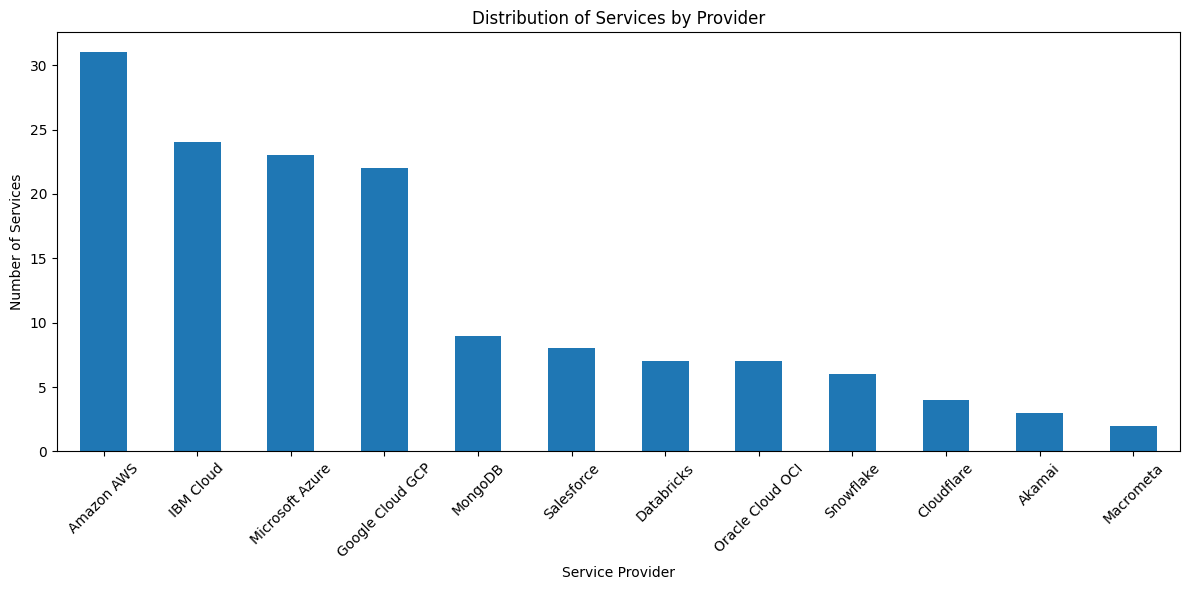

In [9]:
# 1.Service Provider Distribution:
df = df_services
plt.figure(figsize=(12, 6))
df['service_provider'].value_counts().plot(kind='bar')
plt.title('Distribution of Services by Provider')
plt.xlabel('Service Provider')
plt.ylabel('Number of Services')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

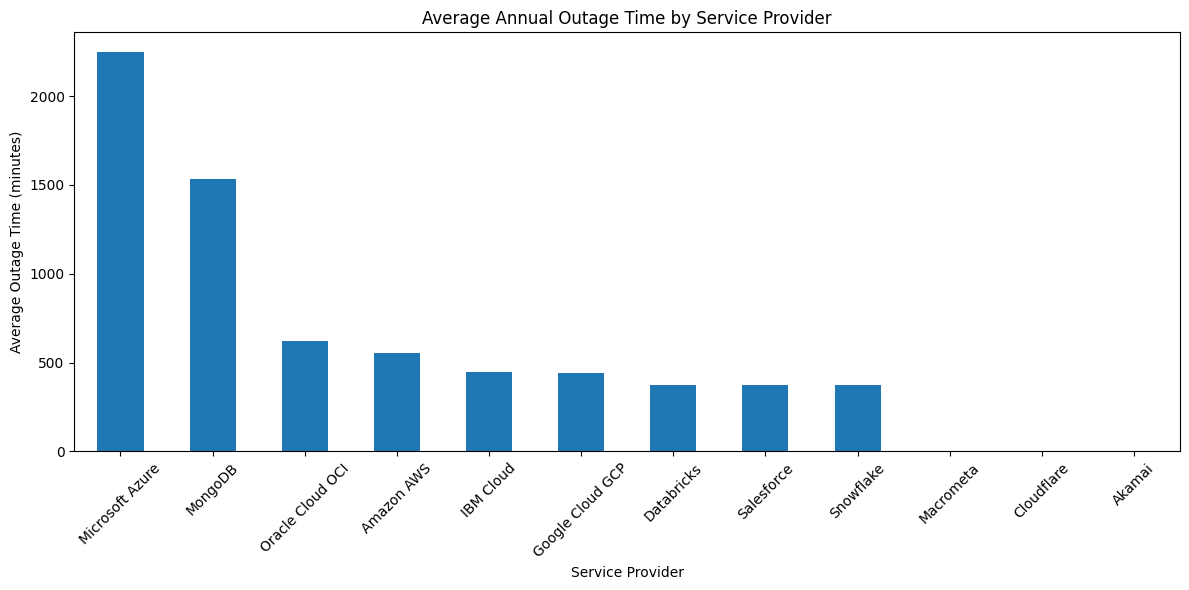

In [10]:
# 2.Average Annual Outage Time by Service Provider:
plt.figure(figsize=(12, 6))
df.groupby('service_provider')['webscraper_annual_period_service_down_per_year_in_minutes'].mean().sort_values(ascending=False).plot(kind='bar')
plt.title('Average Annual Outage Time by Service Provider')
plt.xlabel('Service Provider')
plt.ylabel('Average Outage Time (minutes)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

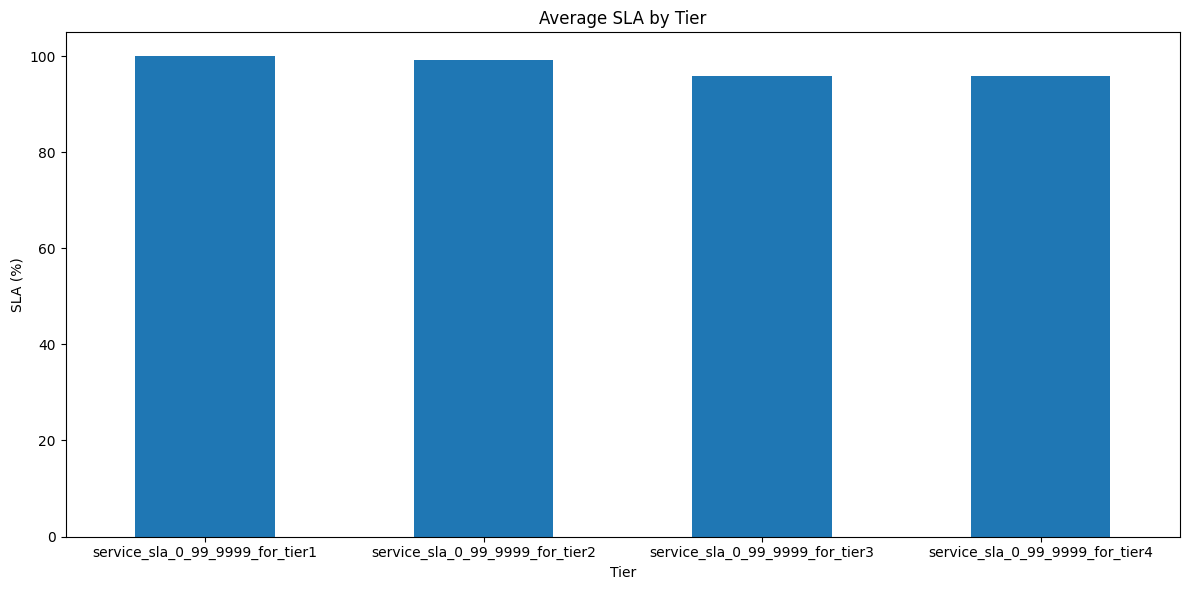

In [11]:
# 3.Service SLA Tiers Comparison:
plt.figure(figsize=(12, 6))
df[['service_sla_0_99_9999_for_tier1', 'service_sla_0_99_9999_for_tier2', 'service_sla_0_99_9999_for_tier3', 'service_sla_0_99_9999_for_tier4']].mean().plot(kind='bar')
plt.title('Average SLA by Tier')
plt.xlabel('Tier')
plt.ylabel('SLA (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

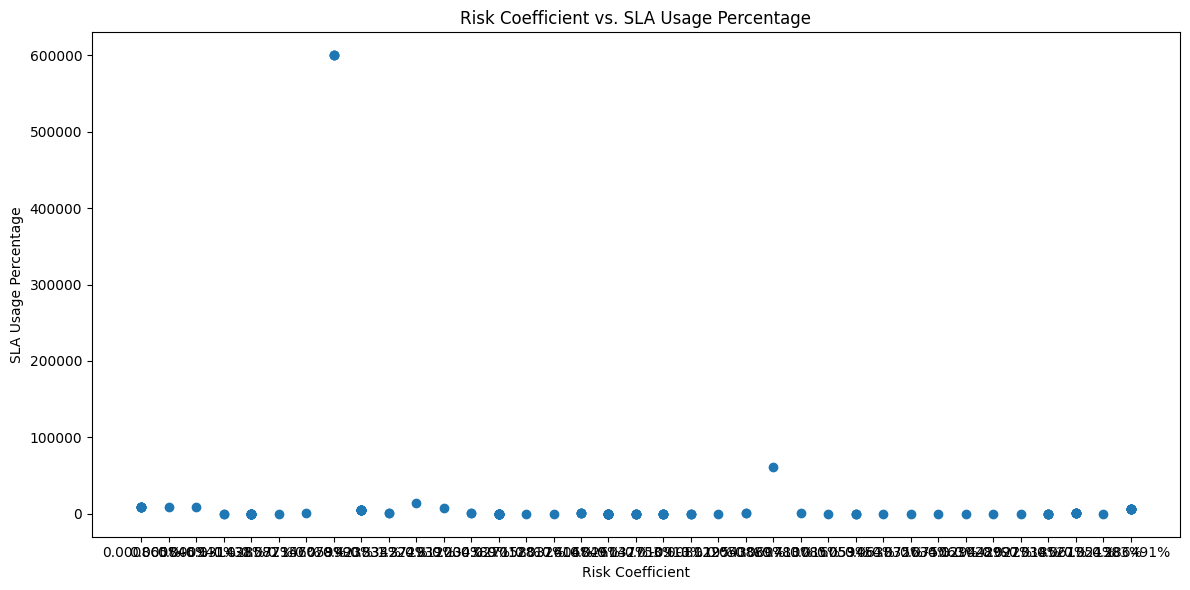

In [12]:
# 4.Risk Coefficient vs. SLA Usage Percentage:
plt.figure(figsize=(12, 6))
plt.scatter(df['riskcoef_per_service_from_gap_expected_actual_time_down'], df['service_sla_usage_percentage'])
plt.title('Risk Coefficient vs. SLA Usage Percentage')
plt.xlabel('Risk Coefficient')
plt.ylabel('SLA Usage Percentage')
plt.tight_layout()
plt.show()

In [13]:
print("done!")

done!


In [14]:
exit()